# Eje 7b — Diferencias finitas paso a paso

Derivados Financieros · QUANt UCEMA · **Pricing avanzado**

Discretizamos la PDE de Black–Scholes en una grilla $(S,t)$ y retrocedemos desde el vencimiento.
Al final tenemos $V(S,t)$ en **toda** la grilla → curva 2D y superficie 3D.

| En este eje | Notebook |
|-------------|----------|
| 07a | Monte Carlo |
| **07b** | Diferencias finitas |
| 07c | QuantLib |
| 07d | Comparación de modelos |

**Plan**
1. PDE de BS
2. Parámetros y tamaño de grilla
3. Spots / tiempos
4. Coeficientes y matriz tridiagonal
5. Payoff + condiciones de borde
6. Retropropagación (esquema)
7. Precio en $S_0$ + check vs BS / `Codigo`
8. Superficie 3D $V(S,t)$
9. Resumen

## 1) Setup

In [1]:
import math
import sys
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

print("OK")

OK


In [2]:
from scipy.interpolate import interp1d
from Codigo.pricing import opcion_europea_bs, opcion_europea_fd, opcion_americana_fd

## 2) PDE de Black–Scholes

$$
\frac{\partial V}{\partial t} + (r-q)S\frac{\partial V}{\partial S}
+ \tfrac12\sigma^2 S^2\frac{\partial^2 V}{\partial S^2} - rV = 0
$$

Con $V(S,T)=\mathrm{payoff}(S)$ y bordes en $S=0$ y $S\to\infty$.

Acá armamos un esquema **explícito didáctico** (como en la clase legacy) sobre la grilla;
la librería `opcion_europea_fd` usa un esquema **implícito** más estable — al final comparamos ambos.

## 3) Parámetros

In [3]:
tipo = "C"
S0, K, T = 100.0, 100.0, 1.0
r, sigma, div = 0.05, 0.25, 0.0

# Grilla: M puntos espaciales, N pasos temporales
# (para el plot 3D usamos valores moderados; subir M,N mejora precisión y costo)
M, N = 80, 400
print(f"{tipo=} {S0=} {K=} {T=} {r=} {sigma=} {div=} {M=} {N=}")

tipo='C' S0=100.0 K=100.0 T=1.0 r=0.05 sigma=0.25 div=0.0 M=80 N=400


## 4) Paso A — grilla de spots y tiempos

$$
S_j = j\cdot \Delta S,\quad j=0,\ldots,M,\quad \Delta S = \frac{2S_0}{M}
$$

$$
t_n = n\cdot \Delta t,\quad n=0,\ldots,N,\quad \Delta t = T/N
$$

In [4]:
dS = 2 * S0 / M
dt = T / N
S_vec = np.linspace(0, 2 * S0, M + 1)
t_vec = np.linspace(0, T, N + 1)
print(f"dS={dS:.4f}  dt={dt:.6f}")
print("S_vec[:5]=", np.round(S_vec[:5], 2), "...", "S_max=", S_vec[-1])
print("t_vec[:3]=", np.round(t_vec[:3], 4), "... T=", t_vec[-1])

dS=2.5000  dt=0.002500
S_vec[:5]= [ 0.   2.5  5.   7.5 10. ] ... S_max= 200.0
t_vec[:3]= [0.     0.0025 0.005 ] ... T= 1.0


## 5) Paso B — coeficientes del esquema explícito

En el nodo espacial $j$ (con $S_j = j\,\Delta S$):

$$
\begin{aligned}
a_j &= \tfrac12 \Delta t\,(\sigma^2 j^2 - (r-q)j) \\
b_j &= 1 - \Delta t\,(\sigma^2 j^2 + r) \\
c_j &= \tfrac12 \Delta t\,(\sigma^2 j^2 + (r-q)j)
\end{aligned}
$$

Armamos la matriz tridiagonal $A$ que actúa sobre el interior $j=1,\ldots,M-1$.

In [5]:
j = np.arange(1, M)
sigma2 = sigma ** 2
aj = 0.5 * dt * (sigma2 * j**2 - (r - div) * j)
bj = 1 - dt * (sigma2 * j**2 + r)
cj = 0.5 * dt * (sigma2 * j**2 + (r - div) * j)

A = np.diag(bj)
for index in range(0, M - 2):
    A[index + 1, index] = aj[index + 1]  # subdiagonal
    A[index, index + 1] = cj[index]      # superdiagonal

print("A shape:", A.shape)
print("diag[:5]=", np.round(np.diag(A)[:5], 4))

A shape: (79, 79)
diag[:5]= [0.9997 0.9992 0.9985 0.9974 0.996 ]


## 6) Paso C — payoff al vencimiento + bordes

- Columna $n=N$ (vencimiento): payoff.
- Fila $S=0$ y $S=S_{\max}$: condiciones de borde call/put (continuas en $t$).

In [6]:
V = np.zeros((M + 1, N + 1))

# Payoff en t=T
if tipo == "C":
    V[:, -1] = np.maximum(S_vec - K, 0.0)
    V[0, :] = 0.0
    # call: S→∞ ≈ S e^{-q τ} − K e^{-r τ}
    tau = T - t_vec
    V[-1, :] = S_vec[-1] * np.exp(-div * tau) - K * np.exp(-r * tau)
else:
    V[:, -1] = np.maximum(K - S_vec, 0.0)
    V[0, :] = K * np.exp(-r * (T - t_vec))
    V[-1, :] = 0.0

print("payoff T (extremos):", V[0, -1], V[M // 2, -1], V[-1, -1])
print("borde S=0 en t=0:", V[0, 0], " | borde Smax t=0:", round(V[-1, 0], 4))

payoff T (extremos): 0.0 0.0 100.0
borde S=0 en t=0: 0.0  | borde Smax t=0: 104.8771


## 7) Paso D — retropropagación

Para $n=N-1,\ldots,0$:

$$
V^{\,n}_{\mathrm{int}} = A\, V^{\,n+1}_{\mathrm{int}} + \text{corrección de bordes}
$$

Así llenamos **toda** la matriz $V_{j,n} = V(S_j, t_n)$.

In [7]:
bordes = np.array([aj[0], cj[-1]])
for n in reversed(range(N)):
    V[1:M, n] = A @ V[1:M, n + 1]
    V[[1, M - 1], n] = V[[1, M - 1], n] + bordes * V[[0, M], n + 1]

print("V llena. shape=", V.shape)
print(f"V(S≈{S0}, t=0) interp ≈ ", float(interp1d(S_vec, V[:, 0])(S0)))

V llena. shape= (81, 401)
V(S≈100.0, t=0) interp ≈  12.327206606183173


## 8) Precio en $S_0$ — manual vs librería vs BS

In [8]:
v_manual = float(interp1d(S_vec, V[:, 0])(S0))
v_fd_lib = opcion_europea_fd(tipo, S0, K, T, r, sigma, div, M=max(M, 120))
v_ame = opcion_americana_fd(tipo, S0, K, T, r, sigma, div, M=max(M, 120))
v_bs = opcion_europea_bs(tipo, S0, K, T, r, sigma, div)
print(f"FD manual (explícito) = {v_manual:.6f}")
print(f"FD lib implícita      = {v_fd_lib:.6f}")
print(f"FD americana          = {v_ame:.6f}")
print(f"Black–Scholes         = {v_bs:.6f}")
print(f"|manual−BS|={abs(v_manual-v_bs):.6f}  |lib−BS|={abs(v_fd_lib-v_bs):.6f}")

FD manual (explícito) = 12.327207
FD lib implícita      = 12.324710
FD americana          = 12.529689
Black–Scholes         = 12.335999
|manual−BS|=0.008792  |lib−BS|=0.011289


## 9) Curva $V(S,0)$

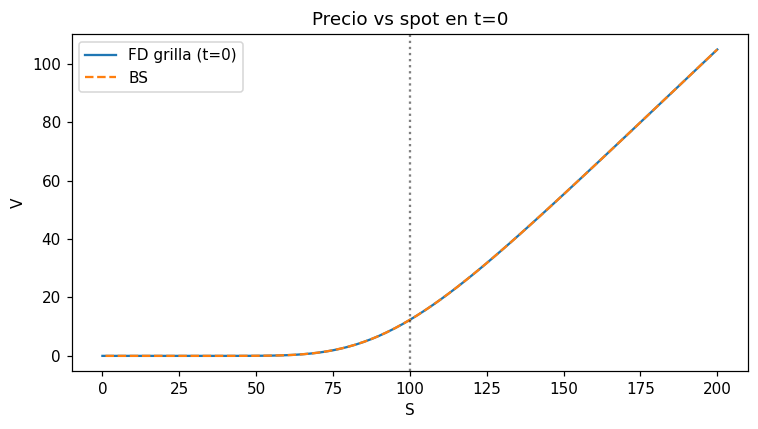

In [9]:
fig, ax = plt.subplots(figsize=(7, 4), dpi=110)
ax.plot(S_vec, V[:, 0], label="FD grilla (t=0)")
S_plot = np.linspace(1, 2 * S0, 60)
ax.plot(S_plot, [opcion_europea_bs(tipo, s, K, T, r, sigma, div) for s in S_plot],
        "--", label="BS")
ax.axvline(K, color="k", ls=":", alpha=0.5)
ax.set_xlabel("S"); ax.set_ylabel("V"); ax.legend()
ax.set_title("Precio vs spot en t=0")
plt.tight_layout(); plt.show()

## 10) Superficie 3D — $V(S,t)$ en toda la grilla

Como el método entrega el precio en **cada** nodo $(S_j,t_n)$, podemos plotear la superficie completa.

mesh shapes: (81, 401) (81, 401) (81, 401)


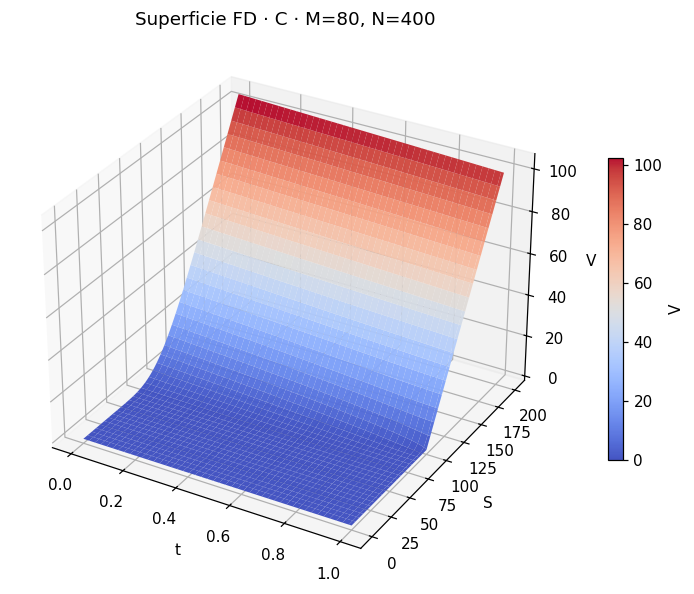

In [10]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

X, Y = np.meshgrid(t_vec, S_vec)
Z = V
print("mesh shapes:", X.shape, Y.shape, Z.shape)

fig = plt.figure(figsize=(9, 5.5), dpi=110)
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="coolwarm", linewidth=0, antialiased=True, alpha=0.95)
ax.set_xlabel("t"); ax.set_ylabel("S"); ax.set_zlabel("V")
ax.set_title(f"Superficie FD · {tipo} · M={M}, N={N}")
fig.colorbar(surf, shrink=0.55, label="V")
plt.tight_layout(); plt.show()

## Resumen

- FD = PDE → grilla → sistema (tridiagonal) → $V(S,t)$ en todos los nodos.
- Ventaja didáctica vs BS: ves la **superficie** completa, no solo un escalar.
- Americana = mismo loop + $\max(\text{continuar},\text{ejercer})$ por nodo (`opcion_americana_fd`).
- El esquema explícito exige $\Delta t$ chico; el implícito de `Codigo` es más robusto.

**Ejercicio:** bajá $N$ a 50 y mirá si el esquema explícito se vuelve inestable (oscilaciones en la curva).

**Siguiente:** **07c** — QuantLib.